In [ ]:
"""
Figure 4 - Modelled contribution of changes in ice surface slope and ice thickness to the change in annual ice displacement observed at LEV6 between 2009 and 2021.
Author: Hannah Picton 
Date: 27th March 2026
Description: This notebook plots the modelled contribution of changes in ice surface slope and ice thickness to the change in annual ice displacement observed at LEV6 between 2009 and 2021,
with uncertainty ranges shown. The calculations used reflect those shown in Equation 3 of the associated manuscript, and the 'driving_stress_calculation' script found in the 'processing' folder of this repository. 
"""

# Import libraries 
import matplotlib.pyplot as plt
import numpy as np
import math
from matplotlib.colors import to_rgba
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
import os 

In [2]:
# Input data and nominal calculations (as used in driving_stress_calculation notebook)
# ==========================================================================================

# Input uncertainty in height measurements (m)
uncertainty_H = 0.5

# Input data used for driving stress calculations 
data = {'lev5_2009_height': 1442.92, 'lev5_2009_bed': 243.05, 'lev5_2021_height': 1438.01, 'lev5_2021_bed': 243.05,
    'lev6_2009_height': 1672.55, 'lev6_2009_bed': 234.31, 'lev6_2021_height': 1670.83, 'lev6_2021_bed': 234.31,
    'dist_2009': 35961.214, 'dist_2021': 35985.827,
    'C_FACTOR': 62.6,'A_FACTOR': 3.0,'B_FACTOR': 3.0}

# Calculate ice thickness
lev6_2009_thickness = data['lev6_2009_height'] - data['lev6_2009_bed']
lev6_2021_thickness = data['lev6_2021_height'] - data['lev6_2021_bed']

# Calculate surface slope
slope_2009 = (data['lev6_2009_height'] - data['lev5_2009_height']) / data['dist_2009']
slope_2021 = (data['lev6_2021_height'] - data['lev5_2021_height']) / data['dist_2021']

# Calculate changes in slope and thickness
delta_s = slope_2021 - slope_2009
delta_thickness = lev6_2021_thickness - lev6_2009_thickness

# Nominal relative changes
X_S = delta_s / slope_2009
X_T = delta_thickness / lev6_2009_thickness

# Nominal total and components
delta_v_nominal = data['C_FACTOR'] * (data['A_FACTOR'] * X_S + data['B_FACTOR'] * X_T)
nom_slope = data['C_FACTOR'] * data['A_FACTOR'] * X_S
nom_thick = data['C_FACTOR'] * data['B_FACTOR'] * X_T

# Uncertainty calculations (as used in driving_stress_calculation notebook)
# ==========================================================================================

# Uncertainty in slope
uncertainty_H_diff = math.sqrt(uncertainty_H**2 + uncertainty_H**2)
delta_slope_2009 = abs(slope_2009) * (uncertainty_H_diff / (data['lev6_2009_height'] - data['lev5_2009_height']))
delta_slope_2021 = abs(slope_2021) * (uncertainty_H_diff / (data['lev6_2021_height'] - data['lev5_2021_height']))
delta_delta_s = math.sqrt(delta_slope_2009**2 + delta_slope_2021**2)

# Uncertainty in thickness change
delta_T = math.sqrt(uncertainty_H**2 + uncertainty_H**2)
delta_delta_T = math.sqrt(delta_T**2 + delta_T**2)

# Fractional uncertainties
fractional_uncertainty_slope = math.sqrt((delta_delta_s / abs(delta_s))**2 + (delta_slope_2009 / abs(slope_2009))**2)
delta_X_S = abs(X_S) * fractional_uncertainty_slope
fractional_uncertainty_thickness = math.sqrt((delta_delta_T / abs(delta_thickness))**2 + (uncertainty_H / lev6_2009_thickness)**2)
delta_X_T = abs(X_T) * fractional_uncertainty_thickness

# Absolute uncertainties in velocity components
unc_slope = data['C_FACTOR'] * data['A_FACTOR'] * delta_X_S
unc_thick = data['C_FACTOR'] * data['B_FACTOR'] * delta_X_T
unc_total = data['C_FACTOR'] * math.sqrt((data['A_FACTOR'] * delta_X_S)**2 + (data['B_FACTOR'] * delta_X_T)**2)

# Store components for plotting
components = {'total': {'nom': delta_v_nominal, 'unc': unc_total, 'range': (delta_v_nominal - unc_total, delta_v_nominal + unc_total)},
    'slope': {'nom': nom_slope, 'unc': unc_slope, 'range': (nom_slope - unc_slope, nom_slope + unc_slope)},
    'thick': {'nom': nom_thick, 'unc': unc_thick, 'range': (nom_thick - unc_thick, nom_thick + unc_thick)}}


In [3]:
# Define plotting functions 
def plus_minus_formatter(value, pos):
    """
    Formats tick labels to show a '+' for positive values, a '-' for negative values, and '0' for zero. Uses 'g' for smart formatting (int or float).
    """
    if value > 0:
        return f"+{value:g}"
    elif value < 0:
        return f"{value:g}" 
    else:
        return "0"

def plus_minus_formatter_1dp(value, pos):
    """
    Formats tick labels to show a '+' for positive values, a '-' for negative values, and '0.0' for zero, ALL to one decimal place.
    """
    if value > 0:
        return f"+{value:.1f}"
    elif value < 0:
        return f"{value:.1f}" 
    else:
        return "0.0"

# Define labels, positions, colors, and data for plotting
labels = [r'Total Modelled' + '\n' + r'Change ($\delta u_s$)',
    r'Surface Slope' + '\n' + r'Contribution ($3\frac{\delta S}{S}$)',
    r'Ice Thickness' + '\n' + r'Contribution ($3\frac{\delta H}{H}$)']
x_pos = np.array([0, 1, 2])
observed_delta_v = 3.2
color_total = to_rgba('#023047')
color_slope = to_rgba('#62b6cb', alpha=0.3)
color_thick = to_rgba('#83c5be', alpha=0.7)
nominal_color = '#000000'
observed_color = 'crimson'
plot_defs = {
    labels[0]: {'x': x_pos[0], 'data': components['total'], 'color': color_total},
    labels[1]: {'x': x_pos[1], 'data': components['slope'], 'color': color_slope},
    labels[2]: {'x': x_pos[2], 'data': components['thick'], 'color': color_thick}}

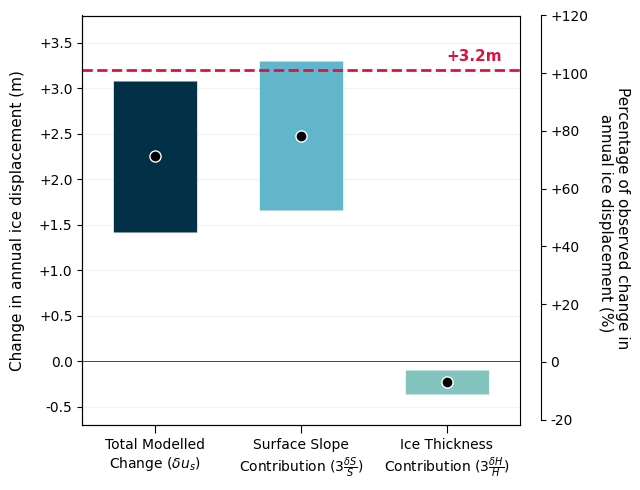

In [4]:
# Plot Modelled contribution of changes in ice surface slope and ice thickness to the change in annual ice displacement observed at LEV6 between 2009 and 2021.
fig, ax1 = plt.subplots(figsize=(6.5,5))
for name, p in plot_defs.items():
    ax1.vlines(p['x'], p['data']['range'][0], p['data']['range'][1], color=p['color'], linewidth=60, alpha=1,zorder=2)
    ax1.plot(p['x'], p['data']['nom'], 'o', color=nominal_color, markersize=8, zorder=5, markeredgecolor='white', markeredgewidth=1)
ax1.axhline(y=observed_delta_v, color=observed_color, linestyle='--', linewidth=2)
ax1.set_ylabel('Change in annual ice displacement (m)', fontsize=11, labelpad=10)
ax1.set_xticks(x_pos)
ax1.tick_params(axis='x', length=6)
ax1.set_xticklabels(labels, fontsize=10)
ax1.set_xlim(-0.5, 2.5)
ax1.set_ylim(-0.7, 3.8)
ax1.grid(axis='y', linestyle='-', alpha=0.1, color='gray')
ax1.yaxis.set_major_formatter(FuncFormatter(plus_minus_formatter_1dp))
ax1.axhline(0, color='black', linestyle='-', linewidth=0.5)
ax1.text(2, observed_delta_v + 0.15, '+3.2m', color=observed_color, va='center', fontsize=11, weight='bold')

# Secondary y-axis offset outward
ax2 = ax1.twinx()
ax2.spines['right'].set_position(('outward', 15))  
ax2.yaxis.set_major_formatter(FuncFormatter(plus_minus_formatter))
primary_ylim = ax1.get_ylim()
sec_ylim = [100 * primary_ylim[0] / observed_delta_v, 100 * primary_ylim[1] / observed_delta_v]
ax2.set_ylim(sec_ylim)
ax2.set_ylabel('Percentage of observed change in \n annual ice displacement (%)', fontsize=11, labelpad=30, rotation=270)
ax2.set_yticks(np.arange(-20, 130, 20))  
ticks = ax2.get_yticks()
min_tick = ticks[0]
max_tick = ticks[-1]
ax2.spines['right'].set_bounds(min_tick, max_tick)

plt.tight_layout()
plt.show()